# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/SATReset_Tuesday_partial.csv',
        ),
        pandas.read_csv(
            'results/SATResetTuesdayControl.csv',
        )
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'], keep = 'last')

data = data[data.problem.isin(data[data.strategy == 'SATResetAtStaleBacktrack'].problem)]

In [5]:
problems = data.problem.str[:3].value_counts().sort_index()
pandas.concat(
    [
        problems[0::3].reset_index(),
        problems[1::3].reset_index(),
        problems[2::3].reset_index(),
    ],
    axis = 1,
).fillna('')

,problem,count,problem,count,problem,count
0,AGT,432,ALG,3704.0,ANA,768.0
1,BIO,48,BOO,1200.0,CAT,1072.0
2,COL,2016,COM,600.0,CSR,7250.0
3,FLD,2248,GEG,8.0,GEO,7168.0
4,GRA,272,GRP,8528.0,HAL,80.0
5,HEN,544,HWC,48.0,HWV,2360.0
6,ITP,800,KLE,2032.0,KRS,2384.0
7,LAT,6064,LCL,7376.0,LDA,400.0
8,MED,96,MGT,1264.0,MSC,200.0
9,MVA,120,NLP,4496.0,NUM,8504.0


# Analysing

In [6]:
control = ['FirstAction', 'LeanCopCut']

In [7]:
data.groupby('strategy').problem.count()

strategy
FirstAction                 12350
LeanCopCut                  12350
SATResetAtStaleAction       12350
SATResetAtStaleBacktrack    12350
SATResetAtTwo               12350
SATResetAtTwoFixedStep      12350
SATSolve                    11968
SATSolveLiteral             12350
Name: problem, dtype: int64

In [8]:
pandas.crosstab(
    data.strategy,
    data.result,
    margins = True,
).sort_values('All')

result,Theorem,Theorem (SAT),All
strategy,,,
FirstAction,1023,0,1023
SATSolve,0,1127,1127
LeanCopCut,1203,0,1203
SATSolveLiteral,0,1705,1705
SATResetAtStaleAction,0,1861,1861
SATResetAtStaleBacktrack,0,1868,1868
SATResetAtTwoFixedStep,0,1933,1933
SATResetAtTwo,0,1962,1962
All,2226,10456,12682


In [130]:
data[data.problem == 'PUZ053-1.p']

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,info,error
37588,PUZ053-1.p,SATResetAtStaleAction,timeout,NaN,False,6276.0,90007.0,CNF_SAT_EPR_NEQ,False,Satisfiable,"literal=choices:5478,forward:100926,unique:724...",NaN
37589,PUZ053-1.p,SATResetAtStaleBacktrack,timeout,NaN,False,6276.0,90014.0,CNF_SAT_EPR_NEQ,False,Satisfiable,"literal=choices:5478,forward:100926,unique:724...",NaN
37590,PUZ053-1.p,SATResetAtTwo,timeout,NaN,False,7977.0,90003.0,CNF_SAT_EPR_NEQ,False,Satisfiable,"literal=choices:6562,forward:122229,unique:128...",NaN
37591,PUZ053-1.p,SATResetAtTwoFixedStep,timeout,NaN,False,7967.0,90006.0,CNF_SAT_EPR_NEQ,False,Satisfiable,"literal=choices:6554,forward:122080,unique:128...",NaN
86454,PUZ053-1.p,FirstAction,timeout,NaN,False,15845.0,120011.0,CNF_SAT_EPR_NEQ,False,Satisfiable,NaN,NaN
86455,PUZ053-1.p,LeanCopCut,timeout,NaN,False,15557.0,120009.0,CNF_SAT_EPR_NEQ,False,Satisfiable,NaN,NaN
86456,PUZ053-1.p,SATSolve,timeout,NaN,False,8895.0,90004.0,CNF_SAT_EPR_NEQ,False,Satisfiable,NaN,NaN
86457,PUZ053-1.p,SATSolveLiteral,timeout,NaN,False,12039.0,120000.0,CNF_SAT_EPR_NEQ,False,Satisfiable,"literal=choices:6245,forward:61132,unique:447,...",NaN


In [131]:
pandas.crosstab(
    data.result.fillna('?'),
    data.problem_declared_status,
)

problem_declared_status,ContradictoryAxioms,CounterSatisfiable,Open,Satisfiable,Theorem,Unknown,Unsatisfiable
result,,,,,,,
?,3140,4291,256,7300,34396,6718,29635
Theorem,28,0,0,0,1450,0,748
Theorem (SAT),177,0,0,0,6195,0,4084


In [9]:
data[data.solved]

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,info,error
0,AGT001+1.p,SATResetAtStaleAction,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,"reset=policy:SATResetAtStaleAction,cuts:on,s:0...",NaN
1,AGT001+1.p,SATResetAtStaleBacktrack,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,"reset=policy:SATResetAtStaleBacktrack,cuts:on,...",NaN
2,AGT001+1.p,SATResetAtTwo,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,"reset=policy:SATResetAtTwo,cuts:on,s:0,r:0,e:0...",NaN
3,AGT001+1.p,SATResetAtTwoFixedStep,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,"reset=policy:SATResetAtTwoFixedStep,cuts:on,s:...",NaN
4,AGT001+2.p,SATResetAtStaleAction,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,"reset=policy:SATResetAtStaleAction,cuts:on,s:0...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
98353,SEU435+1.p,SATSolveLiteral,solved,Theorem (SAT),True,5187.0,7243.0,FOF_THM_RFO_SEQ,False,Theorem,"Theorem (SAT); literal=choices:3211,forward:47...",NaN
98410,SEV515+1.p,FirstAction,solved,Theorem,True,7659.0,1884.0,FOF_THM_RFO_NEQ,False,Theorem,Theorem,NaN
98411,SEV515+1.p,LeanCopCut,solved,Theorem,True,2991.0,567.0,FOF_THM_RFO_NEQ,False,Theorem,Theorem,NaN
98412,SEV515+1.p,SATSolve,solved,Theorem (SAT),True,3017.0,1201.0,FOF_THM_RFO_NEQ,False,Theorem,Theorem (SAT); score=1.0,NaN


In [136]:
data[data.problem_spc_tags.str.contains('FOF')].problem.str[6].value_counts()

problem
+    53301
Name: count, dtype: int64

In [10]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction                 1023
LeanCopCut                  1203
SATResetAtStaleAction       1861
SATResetAtStaleBacktrack    1868
SATResetAtTwo               1962
SATResetAtTwoFixedStep      1933
SATSolve                    1127
SATSolveLiteral             1705
dtype: int64

# Results

<Axes: xlabel='strategy'>

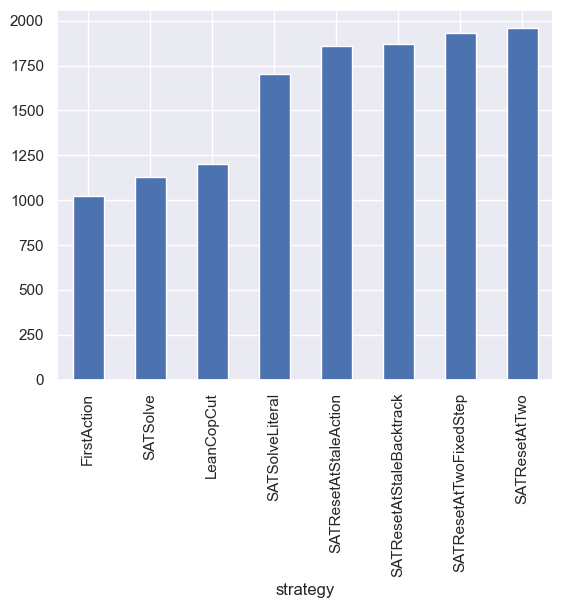

In [11]:
data[data.solved].strategy.value_counts(ascending = True).plot.bar()

In [12]:
data[data.strategy == 'SATResetAtStaleAction'].result.value_counts()

result
Theorem (SAT)    1861
Name: count, dtype: int64

In [13]:
data[data.strategy == 'SATResetAtTwo'].result.value_counts()

result
Theorem (SAT)    1962
Name: count, dtype: int64

In [14]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

In [15]:
pandas.crosstab(merged.strategy_left, merged.strategy_right)

strategy_right,FirstAction,LeanCopCut,SATResetAtStaleAction,SATResetAtStaleBacktrack,SATResetAtTwo,SATResetAtTwoFixedStep,SATSolve,SATSolveLiteral
strategy_left,,,,,,,,
FirstAction,12350,12350,12350,12350,12350,12350,11968,12350
LeanCopCut,12350,12350,12350,12350,12350,12350,11968,12350
SATResetAtStaleAction,12350,12350,12350,12350,12350,12350,11968,12350
SATResetAtStaleBacktrack,12350,12350,12350,12350,12350,12350,11968,12350
SATResetAtTwo,12350,12350,12350,12350,12350,12350,11968,12350
SATResetAtTwoFixedStep,12350,12350,12350,12350,12350,12350,11968,12350
SATSolve,11968,11968,11968,11968,11968,11968,11968,11968
SATSolveLiteral,12350,12350,12350,12350,12350,12350,11968,12350


<Axes: xlabel='Winner', ylabel='Loser'>

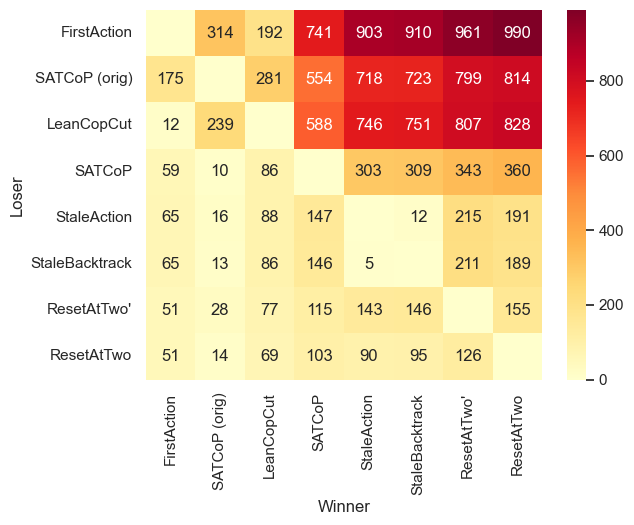

In [83]:
values = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
)

order = values.groupby(level = 'strategy_right').sum().sort_values().index

results = (
    values
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
    .reindex(index = order, columns = order, fill_value = 0)
)

renamer = {
    'SATSolve': 'SATCoP (orig)',
    'SATSolveLiteral': 'SATCoP',
    'SATResetAtStaleAction': 'StaleAction',
	'SATResetAtStaleBacktrack': 'StaleBacktrack',
	'SATResetBandit': 'Bandit',
    'SATResetAtTwoFixedStep': 'ResetAtTwo\'',
    'SATResetAtTwo': 'ResetAtTwo',
}

cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
cols = results.columns
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Loser', columns = 'Winner').
    rename(index = renamer).
    rename(columns = renamer)
)

seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(results.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
)
# pyplot.title(f'Winners and losers of different SAT policies. Total of {merged.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot_29Apr.png', bbox_inches = 'tight', dpi = 400)

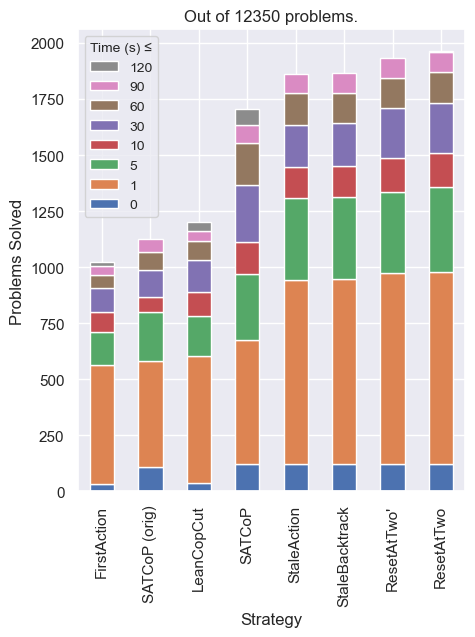

In [135]:
pyplot.rcParams["figure.figsize"] = (5,6)

times = [0, 1, 5, 10, 30, 60, 90, 120]
solved_time = Series(
    numpy.select(
        [data.solved & (data.time_ms <= 1000 * x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack().reindex(order).rename(index = renamer)
b.plot.bar(stacked = True)
pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Time (s) ≤', title_fontsize = 'small')

pyplot.title(f'Out of {data.problem.nunique()} problems.')
None

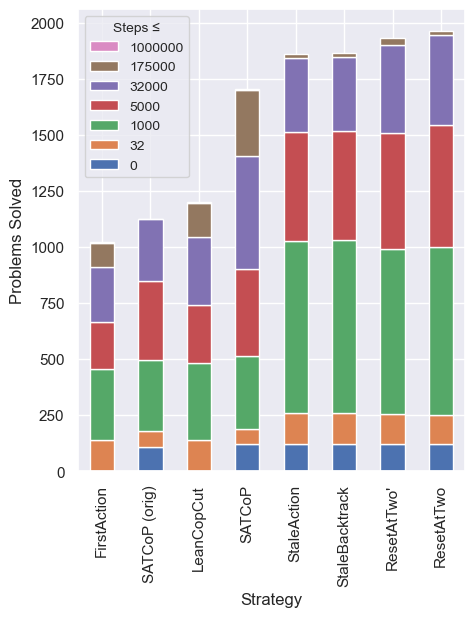

In [106]:
pyplot.rcParams["figure.figsize"] = (5,6)

times = [0, 32, 1000, 5000, 32000, 175000, 1000000]
solved_time = Series(
    numpy.select(
        [data.solved & (data.steps <= x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack().reindex(order).rename(index = renamer)
b.plot.bar(stacked = True)
pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Steps ≤', title_fontsize = 'small')